<a href="https://colab.research.google.com/github/kudinha/4100-Lab-Dialysis/blob/code/Analysis_code_10_14_2%3A39.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final Code for Dialysis

In [73]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Setup

In [74]:
!pip install -q uncertainties

In [75]:
import re, glob, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import odr
from scipy.optimize import curve_fit
from uncertainties import ufloat, correlated_values, umath, unumpy as unp
from IPython.display import display
from google.colab import drive


drive.mount('/content/drive')
warnings.filterwarnings('ignore')
DATA_DIR = Path('/content/drive/MyDrive/Dialysis Lab')     # data files (.xlsx and/or .zip)
OUT_DIR = DATA_DIR / 'Dialysis_Output'                     # figures + results saved here
FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.family': 'sans-serif',
                     'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10,
                     'axes.grid': True, 'grid.alpha': 0.3})

print(DATA_DIR.exists())
print(list(DATA_DIR.iterdir()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True
[PosixPath('/content/drive/MyDrive/Dialysis Lab/Dialysis_Output'), PosixPath('/content/drive/MyDrive/Dialysis Lab/NaCl-316_0.067M_10-12_Calibration.xlsx'), PosixPath('/content/drive/MyDrive/Dialysis Lab/KCl-220_0.067M_10-07.xlsx'), PosixPath('/content/drive/MyDrive/Dialysis Lab/NaCl-233_0.1M_10-12.xlsx'), PosixPath('/content/drive/MyDrive/Dialysis Lab/KCl_0.1M_10-05_Calibration.xlsx'), PosixPath('/content/drive/MyDrive/Dialysis Lab/NaCl-424_0.033M_10-12.xlsx'), PosixPath('/content/drive/MyDrive/Dialysis Lab/KCl-412_0.1M_10-05.xlsx'), PosixPath('/content/drive/MyDrive/Dialysis Lab/lab2_flow_calibration.xlsx'), PosixPath('/content/drive/MyDrive/Dialysis Lab/KCl-335_0.033_10-07_Calibration.xlsx'), PosixPath('/content/drive/MyDrive/Dialysis Lab/KCl-235_0.1M_10-05.xlsx'), PosixPath('/content/drive/MyDrive/Dialysis Lab/KCl-245-5_0.1M_10-05.xlsx'), PosixPath('/

Constants

In [76]:
T_C = 25.0                                    # stream temperature [°C]
T_K = T_C + 273.15
MU = 2.414e-5 * 10 ** (247.8 / (T_K - 140))   # water viscosity [Pa s]
NU = MU / 997.0                               # kinematic viscosity [m^2/s]

# Salt: limiting ionic conductivities λ [S cm^2/mol] and charges (cation, anion), 25 °C
SALTS = {'KCl':  dict(ions=((73.5, 1), (76.3, 1)), color='tab:blue'),
         'NaCl': dict(ions=((50.1, 1), (76.3, 1)), color='tab:red')}

# Optiflux F16NR
A, L = 1.5, 0.260                             # membrane area [m^2], fiber length [m]
D_I, Z = 200e-6, 45e-6                        # fiber ID, wall thickness [m]
SHELL_OD, SHELL_T = 42.9e-3, 3e-3             # shell OD, wall [m]

# Uncertainties
FLOW_ERR = {'small': 0.05, 'big': 0.10}       # rotameter reading error [GPH] (2-GPH / 5-GPH meters)
VOL_ERR, TIME_ERR = 2.0, 1.0                  # bucket test: volume [mL], stopwatch [s]
STD_REL_ERR = 0.01                            # 1% error on prepared standard concentrations
ADC_Q = (5 / 1023) / np.sqrt(12)              # ADC quantization σ [V]

# Analysis choices
STEADY_WINDOW_S = 60                          # steady state = last N seconds of each run
EXCLUDE = {}                                  # drop from ε/τ later: {('file.xlsx', run_no): 'reason'}
ET_SOURCE = dict(salt='KCl', date='10-05')    # Day-1 runs that define the final ε/τ

GPH = 3.785411784e-3 / 3600                   # GPH -> m^3/s
STREAMS = ['TI', 'TO', 'SI', 'SO']
STREAM_NAME = {'TI': 'Tube In', 'TO': 'Tube Out', 'SI': 'Shell In', 'SO': 'Shell Out'}
V_COLS = {'TI': 'Tube_In_A0_V', 'TO': 'Tube_Out_A1_V', 'SI': 'Shell_In_A2_V', 'SO': 'Shell_Out_A3_V'}

Geometry and diffusivities

In [77]:
R_I, R_O = D_I / 2, D_I / 2 + Z
N_FIB = A / (np.pi * D_I * L)                              # A = N π D_I L
A_TUBE = N_FIB * np.pi * R_I**2                            # lumen flow area
A_SHELL = np.pi / 4 * ((SHELL_OD - 2 * SHELL_T)**2 - N_FIB * (2 * R_O)**2)   # shell flow area A_c
D_H = 4 * A_SHELL / (N_FIB * np.pi * 2 * R_O)              # eqn [6]: D_H = 4 A_c / P
MEM = R_I * np.log(R_O / R_I) / (R_O - R_I)                # geometric factor on 1/k_m in eqn [2]

for s, p in SALTS.items():
    # Nernst–Haskell: D_AB = (RT/F²)(1/z+ + 1/z−) / (1/λ+ + 1/λ−), then scaled T/μ from 25 °C
    (lp, zp), (lm, zm) = p['ions']
    d25 = 8.314 * 298.15 / 96485.0**2 * (1 / zp + 1 / zm) / (1 / (lp * 1e-4) + 1 / (lm * 1e-4))
    p['D'] = d25 * (T_K / 298.15) * (2.414e-5 * 10 ** (247.8 / (298.15 - 140)) / MU)
    p['Sc'] = NU / p['D']                                  # eqn [5]: Sc = ν / D_AB
    print(f"{s}: D_AB = {p['D']:.3e} m²/s, Sc = {p['Sc']:.0f}")
print(f'{N_FIB:.0f} fibers, D_H = {D_H * 1e6:.0f} µm')

KCl: D_AB = 1.994e-09 m²/s, Sc = 448
NaCl: D_AB = 1.611e-09 m²/s, Sc = 555
9182 fibers, D_H = 221 µm


File Loading

In [78]:
for z in glob.glob(str(DATA_DIR / '*.zip')):
    with zipfile.ZipFile(z) as zf:
        zf.extractall(OUT_DIR / '_unzipped' / Path(z).stem)

files = {}
for p in list(DATA_DIR.glob('*.xlsx')) + list((OUT_DIR / '_unzipped').rglob('*.xlsx')):
    if 'compiled' not in p.name.lower():
        files.setdefault(p.name, p)
FLOW_FILE = next(p for n, p in files.items() if 'flow' in n.lower())
RUN_FILES = [p for n, p in files.items() if re.match(r'^(%s)[-_]' % '|'.join(SALTS), n)]


def v_stat(trace, tag):
    """Steady-state voltage: mean of the window; σ = scatter ⊕ ADC quantization."""
    return ufloat(trace.mean(), np.hypot(trace.std(ddof=1), ADC_Q), tag)


def read_file(path):
    """One dict per run. Every run in a file ending in '_Calibration' is a calibration run."""
    xl = pd.read_excel(path, sheet_name=None)
    salt = re.match(r'^([A-Za-z]+)', path.name).group(1)
    conc = float(re.search(r'_([\d.]+)M?(?=_)', path.name).group(1))
    is_cal = path.stem.lower().endswith('_calibration')
    runs = []
    for _, s in xl['Summary'].dropna(subset=['Run Number']).iterrows():
        n = int(s['Run Number'])
        sheet = next(k for k in xl if re.match(rf'RUN {n}\b', k))
        d = xl[sheet].dropna(subset=['Elapsed_Time_Sec'])
        ss = d[d['Elapsed_Time_Sec'] >= d['Elapsed_Time_Sec'].max() - STEADY_WINDOW_S]
        V = {k: v_stat(ss[V_COLS[k]].values, f'V {STREAM_NAME[k]}') for k in STREAMS}
        rd = {k: (float(s[f'{STREAM_NAME[k]} Low (GPH)'] or 0), float(s[f'{STREAM_NAME[k]} High (GPH)'] or 0))
              for k in STREAMS}                            # (2-GPH, 5-GPH) meter readings
        runs.append(dict(file=path.name, salt=salt, conc=conc, date=str(s['Date']), run=n, rd=rd, V=V, is_cal=is_cal))
    return runs


ALL = [r for p in RUN_FILES for r in read_file(p)]
CAL_RUNS = [r for r in ALL if r['is_cal']]
RUNS = [r for r in ALL if not r['is_cal']]
display(pd.DataFrame(ALL).assign(type=lambda d: np.where(d.is_cal, 'calibration', 'dialysis'))
        .groupby(['salt', 'conc', 'file', 'type']).run.apply(list).to_frame('runs'))

runs
salt conc  file                                   type                           
KCl  0.033 KCl-335_0.033_10-07.xlsx               dialysis     [1, 2, 3, 4, 5, 6]
           KCl-335_0.033_10-07_Calibration.xlsx   calibration              [1, 2]
     0.067 KCl-220_0.067M_10-07.xlsx              dialysis        [1, 2, 3, 4, 5]
     0.100 KCl-235_0.1M_10-05.xlsx                dialysis                    [1]
           KCl-245-5_0.1M_10-05.xlsx              dialysis     [1, 2, 3, 4, 5, 6]
           KCl-412_0.1M_10-05.xlsx                dialysis           [1, 2, 3, 4]
           KCl_0.1M_10-05_Calibration.xlsx        calibration                 [1]
NaCl 0.033 NaCl-424_0.033M_10-12.xlsx             dialysis              [1, 2, 3]
           NaCl_0.033M_Calibration.xlsx           calibration                 [1]
     0.067 NaCl-316_0.067M_10-12_Calibration.xlsx calibration                 [1]
           NaCl-330_0.067M_10-12.xlsx             dialysis           [1, 2, 3, 4]
     0.100 NaCl-215_0.1M_10-12_Calibration.xlsx   calibration           [1, 2, 3]
           NaCl-233_0.1M_10-12.xlsx               dialysis        [1, 2, 3, 4, 5]

Flowmeter Calibration

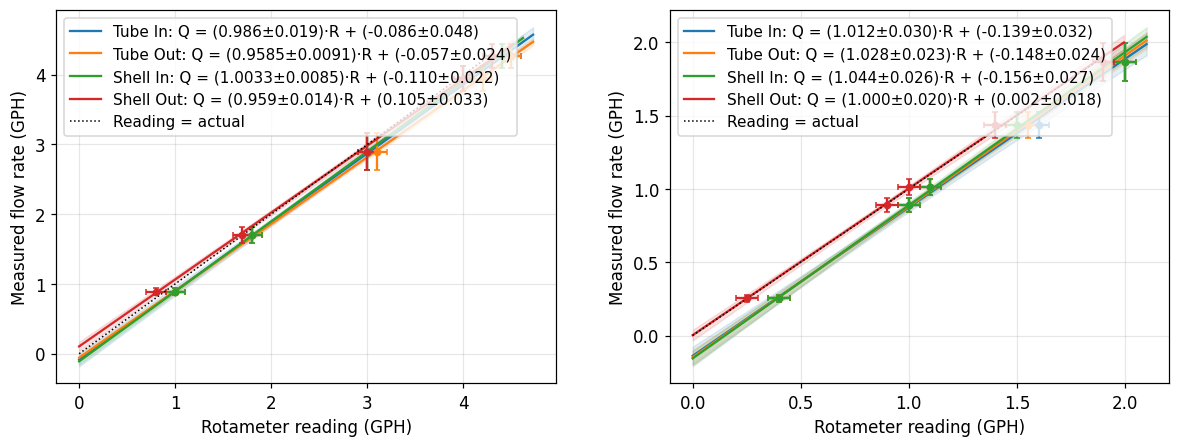

In [79]:
raw = pd.read_excel(FLOW_FILE, header=None)


def extract(raw, tag, n_rows=6, n_cols=5):
    """One calibration table (4 meter rows + volume + time), located by its label cell."""
    r0, c0 = next((r, c) for r in range(raw.shape[0]) for c in range(raw.shape[1])
                  if isinstance(raw.iat[r, c], str) and tag in raw.iat[r, c].lower())
    block = raw.iloc[r0:r0 + n_rows, c0:c0 + n_cols + 1]
    data = block.iloc[:, 1:].apply(pd.to_numeric, errors='coerce')
    data.index = block.iloc[:, 0].astype(str).str.strip().str.lower()
    return data


cal = {}                                                   # (size, stream) -> (m, b)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, size in zip(axes, ('big', 'small')):
    tbl = extract(raw, f'{size} tube in')
    row = lambda key: tbl.loc[[i for i in tbl.index if key in i][0]].values.astype(float)
    Q_u = unp.uarray(row('volume'), VOL_ERR) / unp.uarray(row('time'), TIME_ERR) * 3600 / 3785.41   # Q = V/t [GPH]
    y, ye = unp.nominal_values(Q_u), unp.std_devs(Q_u)
    for st in STREAMS:
        x = row(f'{size} {STREAM_NAME[st].lower()}')
        res = odr.ODR(odr.RealData(x, y, sx=np.full_like(x, FLOW_ERR[size]), sy=ye), odr.unilinear).run()
        m, b = correlated_values(res.beta, res.cov_beta * res.res_var)
        cal[(size, st)] = (m, b)
        xx = np.linspace(0, x.max() * 1.05, 50)
        fit = m * xx + b
        line = ax.plot(xx, unp.nominal_values(fit), label=f'{STREAM_NAME[st]}: Q = ({m:.2uP})·R + ({b:.2uP})')[0]
        ax.fill_between(xx, unp.nominal_values(fit) - 1.96 * unp.std_devs(fit),
                        unp.nominal_values(fit) + 1.96 * unp.std_devs(fit), color=line.get_color(), alpha=0.12)
        ax.errorbar(x, y, xerr=FLOW_ERR[size], yerr=ye, fmt='o', ms=4, capsize=2, color=line.get_color())
    ax.plot([0, x.max()], [0, x.max()], 'k:', lw=1, label='Reading = actual')
    ax.set(xlabel='Rotameter reading (GPH)', ylabel='Measured flow rate (GPH)')
    ax.legend(loc='upper left')
fig.tight_layout(); fig.savefig(FIG_DIR / '00_flowmeter_calibration.png'); plt.show()


def flow(st, low, high, tag):
    """Calibrated flow [m^3/s] = Σ (m·reading + b) over the stream's 2-GPH and 5-GPH meters.
    Reading error per handout: max(5% of reading, FLOW_ERR)."""
    q = 0
    for r, size in ((low, 'small'), (high, 'big')):
        if r > 0:
            m, b = cal[(size, st)]
            q = q + m * ufloat(r, max(0.05 * r, FLOW_ERR[size]), f'{tag} reading') + b
    return q * GPH

Conductivity Calibration

KCl: 3 calibration runs at [0.033, 0.1] M -> C = aV (zero intercept)
NaCl: 5 calibration runs at [0.033, 0.067, 0.1] M -> C = aV (zero intercept)


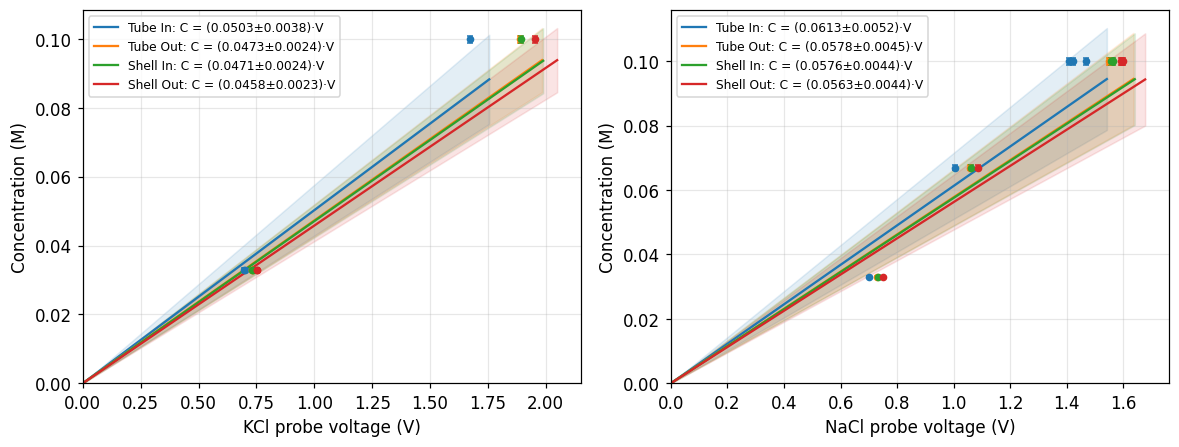

In [80]:
# ============================================================
# CONDUCTIVITY CALIBRATION — LINEAR, ZERO INTERCEPT
# ============================================================

COND_CAL = {}

fig, axes = plt.subplots(1, len(SALTS), figsize=(11, 4.2))

for ax, salt in zip(axes, SALTS):

    cr = [r for r in CAL_RUNS if r['salt'] == salt]

    if not cr:
        raise ValueError(f'No {salt} *_Calibration files found.')

    concs = sorted({r['conc'] for r in cr})

    print(
        f"{salt}: {len(cr)} calibration runs at {concs} M "
        "-> C = aV (zero intercept)"
    )

    for st in STREAMS:

        V = np.array([r['V'][st].n for r in cr])
        C = np.array([r['conc'] for r in cr])

        # Concentration uncertainty
        sC = STD_REL_ERR * C

        # Weighted linear regression with intercept fixed at zero
        p, cov = curve_fit(
            lambda v, a: a * v,
            V,
            C,
            sigma=sC,
            absolute_sigma=len(V) <= 1
        )

        a = ufloat(
            p[0],
            np.sqrt(cov[0, 0]),
            f'cond cal {salt}'
        )

        # Preserve original data structure for compatibility
        b = ufloat(0, 0)

        COND_CAL[(salt, st)] = (a, b)

        # Plot calibration
        vv = np.linspace(0, V.max() * 1.05, 100)

        fit = a * vv

        line = ax.plot(
            vv,
            unp.nominal_values(fit),
            label=f'{STREAM_NAME[st]}: C = ({a:.2uP})·V'
        )[0]

        # 95% confidence band
        ax.fill_between(
            vv,
            unp.nominal_values(fit) - 1.96 * unp.std_devs(fit),
            unp.nominal_values(fit) + 1.96 * unp.std_devs(fit),
            color=line.get_color(),
            alpha=0.12
        )

        # Experimental calibration points
        ax.errorbar(
            V,
            C,
            yerr=sC,
            fmt='o',
            ms=4,
            capsize=2,
            color=line.get_color()
        )

    ax.set(
        xlabel=f'{salt} probe voltage (V)',
        ylabel='Concentration (M)',
        xlim=(0, None),
        ylim=(0, None)
    )

    ax.legend(loc='upper left', fontsize=8)

fig.tight_layout()
fig.savefig(FIG_DIR / '01_conductivity_calibration.png')
plt.show()


def conc(salt, st, V):
    """Stream concentration [mol/m^3] from probe voltage."""
    a, b = COND_CAL[(salt, st)]
    return a * V * 1000

Per run analysis

In [81]:
def sh_tube(Re, Sc):  return 3.66 + Re**2.24 * (Sc * D_I / L)**(1 / 3)    # eqn [4]
def sh_shell(Re, Sc): return 1.39 * Re**2.11 * (Sc * D_H / L)**(1 / 3)    # eqn [7]


def analyze(r):
    D, Sc = SALTS[r['salt']]['D'], SALTS[r['salt']]['Sc']
    Q = {k: flow(k, *r['rd'][k], STREAM_NAME[k]) for k in STREAMS}       # m^3/s
    C = {k: conc(r['salt'], k, r['V'][k]) for k in STREAMS}               # mol/m^3

    # (a) Material balance: salt in = salt out, water in = water out
    N_in, N_out = Q['TI'] * C['TI'] + Q['SI'] * C['SI'], Q['TO'] * C['TO'] + Q['SO'] * C['SO']
    dW, dQ = N_in - N_out, (Q['TI'] + Q['SI']) - (Q['TO'] + Q['SO'])

    # (b) K_A from W_R = K_A·A·ΔC_lm   (eqns [9]–[11], counter-current)
    W_R = Q['TI'] * C['TI'] - Q['TO'] * C['TO']
    d1, d2 = C['TO'] - C['SI'], C['TI'] - C['SO']
    C_lm = (d1 - d2) / umath.log(d1 / d2) if d1.n > 0 and d2.n > 0 else ufloat(np.nan, 0)
    K = W_R / (A * C_lm)

    # (c) Boundary layers from Sherwood correlations (eqns [3]–[7]); Re from mean in/out flow
    Re_t = (Q['TI'] + Q['TO']) / 2 / A_TUBE * D_I / NU
    Re_s = (Q['SI'] + Q['SO']) / 2 / A_SHELL * D_H / NU
    k_R, k_D = sh_tube(Re_t, Sc) * D / D_I, sh_shell(Re_s, Sc) * D / D_H

    # (d) Membrane: resistances in series, eqn [2]  ->  ε/τ = k_m·z / D_AB, eqn [8]
    R_R, R_D = 1 / k_R, R_I / (R_O * k_D)
    R_M = 1 / K - R_R - R_D
    k_m = MEM / R_M
    flags = '; '.join(m for bad, m in [(R_M.n <= 0, 'membrane resistance ≤ 0'),
                                       (abs(dW.n) > 2 * dW.s, 'salt balance fails (2σ)'),
                                       (abs(dQ.n) > 2 * dQ.s, 'water balance fails (2σ)')] if bad)
    return dict(r, Q=Q, C=C, N_in=N_in, dW=dW, dQ=dQ, W_R=W_R, C_lm=C_lm, K=K, Re_t=Re_t, Re_s=Re_s,
                k_R=k_R, k_D=k_D, R_R=R_R, R_D=R_D, k_m=k_m, et=k_m * Z / D, flags=flags)


RES = [analyze(r) for r in RUNS]
for f in {r['file'] for r in RES}:                         # which side was varied in each file (for plots)
    rs = [r for r in RES if r['file'] == f]
    rel = lambda k: np.ptp([r[k].n for r in rs]) / np.mean([r[k].n for r in rs])
    for r in rs:
        r['varied'] = 'tube' if rel('Re_t') > rel('Re_s') else 'shell'

Final epsilon/tau, k_m error

In [82]:
def weighted_mean(vals):
    w = np.array([1 / v.s**2 for v in vals])
    mean = sum(wi * v for wi, v in zip(w, vals)) / w.sum()
    chi2 = np.sum(w * (np.array([v.n for v in vals]) - mean.n)**2) / max(len(vals) - 1, 1)
    return (mean if chi2 <= 1 else mean.n + (mean - mean.n) * np.sqrt(chi2)), chi2


def used(rows):
    return [r for r in rows if np.isfinite(r['et'].n) and (r['file'], r['run']) not in EXCLUDE]


all_kcl = [r for r in RES if r['salt'] == 'KCl']
ET, chi2 = weighted_mean([r['et'] for r in used(all_kcl)])
print(f'ε/τ (all KCl, n = {len(used(all_kcl))}) = {ET:.2uP}   (χ²_red = {chi2:.2f})')
display(pd.DataFrame({'Run': [f"{r['file'].split('_')[0]} r{r['run']}" for r in all_kcl],
                      'ε/τ': [f"{r['et']:.2uP}" for r in all_kcl],
                      'flags': [r['flags'] for r in all_kcl]}))

# Same weighted average per salt / feed concentration (is ε/τ a membrane constant?)
display(pd.DataFrame([{'salt': s, 'C_feed (M)': c, 'n': len(rr), 'ε/τ': f'{weighted_mean([r["et"] for r in rr])[0]:.2uP}'}
                      for s, c in sorted({(r['salt'], r['conc']) for r in RES})
                      for rr in [used([r for r in RES if (r['salt'], r['conc']) == (s, c)])]]))

# k_m,th = (ε/τ)·D_AB / z and K_A,th from eqn [2] at each run's own Re
for r in RES:
    r['k_m_th'] = ET * SALTS[r['salt']]['D'] / Z
    r['K_th'] = 1 / (r['R_R'] + MEM / r['k_m_th'] + r['R_D'])
for s in SALTS:
    print(f"{s}: k_m = (ε/τ)·D_AB/z = {ET * SALTS[s]['D'] / Z * 1e6:.2uP} µm/s")

ε/τ (all KCl, n = 20) = 0.144±0.017   (χ²_red = 0.33)


,Run,ε/τ,flags
0,KCl-220 r1,0.20±0.15,
1,KCl-220 r2,0.162±0.031,
2,KCl-220 r3,0.162±0.041,
3,KCl-220 r4,0.148±0.023,
4,KCl-220 r5,nan±nan,
5,KCl-412 r1,0.17±0.12,
6,KCl-412 r2,0.24±0.38,
7,KCl-412 r3,0.30±0.24,
8,KCl-412 r4,0.150±0.029,
9,KCl-235 r1,nan±nan,


,salt,C_feed (M),n,ε/τ
0,KCl,0.033,6,0.157±0.026
1,KCl,0.067,4,0.155±0.027
2,KCl,0.100,10,0.138±0.014
3,NaCl,0.033,3,0.188±0.044
4,NaCl,0.067,4,0.182±0.037
5,NaCl,0.100,5,0.158±0.030


KCl: k_m = (ε/τ)·D_AB/z = 6.38±0.77 µm/s
NaCl: k_m = (ε/τ)·D_AB/z = 5.15±0.62 µm/s


Error in Ka

In [83]:
case = min((r for r in all_kcl if not r['flags']),
           key=lambda r: abs(r['Q']['TI'].n / GPH - 2) + abs(r['Q']['SI'].n / GPH - 2))
comp = pd.Series({(v.tag or 'flowmeter cal (m, b)'): c for v, c in case['K'].error_components().items()})
comp = comp.groupby(level=0).apply(lambda x: np.sqrt((x**2).sum())).sort_values(ascending=False)
print(f"{case['file']} run {case['run']}: K_A = {case['K'] * 1e6:.2uP} µm/s")
display(pd.DataFrame({'σ (µm/s)': comp * 1e6, '% of variance': (comp**2 / (comp**2).sum() * 100).round(1)}))

KCl-245-5_0.1M_10-05.xlsx run 1: K_A = 5.28±0.98 µm/s


,σ (µm/s),% of variance
Tube In reading,0.354503,68.4
cond cal KCl,0.216160,25.4
Tube Out reading,0.077227,3.2
V Tube Out,0.045351,1.1
V Shell Out,0.041283,0.9
"flowmeter cal (m, b)",0.035492,0.7
V Tube In,0.016491,0.1
V Shell In,0.009538,0.0


Experimental K_a v theoretical Re

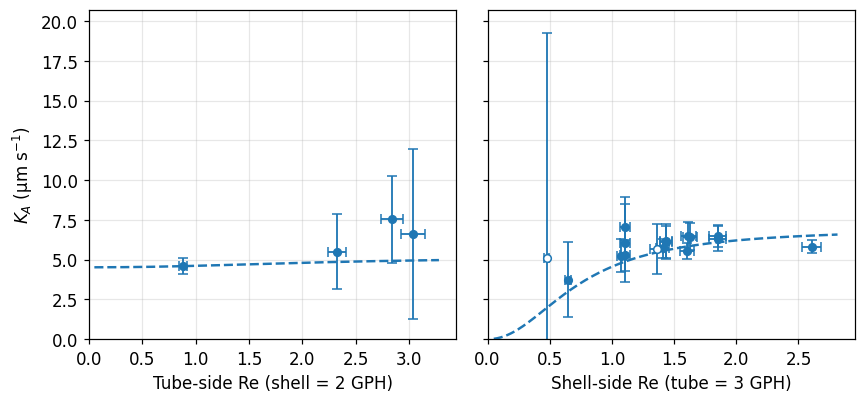

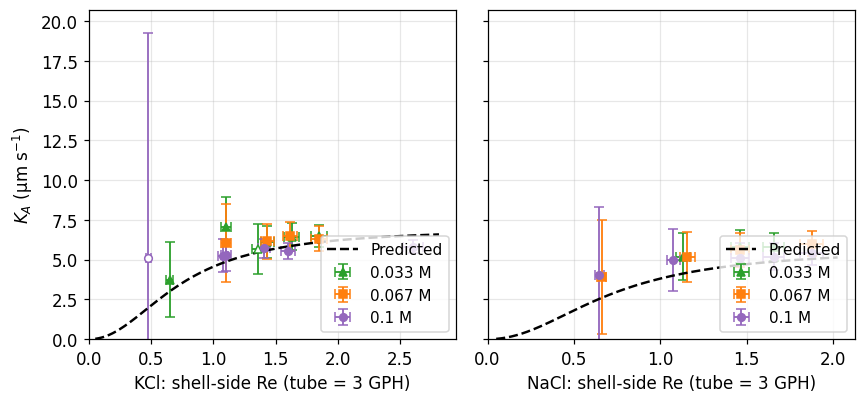

In [84]:
def K_theory(salt, Re_t, Re_s):
    D, Sc = SALTS[salt]['D'], SALTS[salt]['Sc']
    return 1 / (D_I / (sh_tube(Re_t, Sc) * D) + MEM * Z / (ET.n * D) + R_I / R_O * D_H / (sh_shell(Re_s, Sc) * D))


def ka_plot(ax, rows, vary, color, marker, label=None, theory_color=None, theory_label=None):
    x_key, held_key = ('Re_t', 'Re_s') if vary == 'tube' else ('Re_s', 'Re_t')
    rows = [r for r in rows if np.isfinite(r['K'].n)]
    for grp, filled in (([r for r in rows if not r['flags']], True), ([r for r in rows if r['flags']], False)):
        if grp:
            ax.errorbar([r[x_key].n for r in grp], [r['K'].n * 1e6 for r in grp],
                        xerr=[r[x_key].s for r in grp], yerr=[r['K'].s * 1e6 for r in grp],
                        fmt=marker, ms=5, capsize=3, elinewidth=1.2, color=color,
                        mfc=color if filled else 'white', label=label if filled else None)
    if theory_color:
        held = np.mean([r[held_key].n for r in rows])
        xx = np.linspace(0.05, max(r[x_key].n for r in rows) * 1.08, 200)
        yy = K_theory(rows[0]['salt'], xx, held) if vary == 'tube' else K_theory(rows[0]['salt'], held, xx)
        ax.plot(xx, yy * 1e6, '--', color=theory_color, lw=1.6, label=theory_label)


def held_gph(rows, k):
    return np.mean([r['Q'][k].n for r in rows]) / GPH


# Day 1: tube varied | shell varied
c = SALTS['KCl']['color']
day1 = {v: [r for r in all_kcl if r['varied'] == v] for v in ('tube', 'shell')}
fig, axes = plt.subplots(1, 2, figsize=(8, 3.8), sharey=True)
for ax, v in zip(axes, day1):
    ka_plot(ax, day1[v], v, c, 'o', theory_color=c)
axes[0].set_xlabel(f"Tube-side Re (shell = {held_gph(day1['tube'], 'SI'):.0f} GPH)")
axes[1].set_xlabel(f"Shell-side Re (tube = {held_gph(day1['shell'], 'TI'):.0f} GPH)")
axes[1].set_xlabel(f"Shell-side Re (tube = {held_gph(day1['shell'], 'TI'):.0f} GPH)")
axes[0].set_ylabel(r'$K_A$ (μm s$^{-1}$)')
for ax in axes: ax.set_xlim(left=0); ax.set_ylim(bottom=0)
fig.tight_layout(); fig.savefig(FIG_DIR / '02_Day1_KA_vs_Re.png', bbox_inches='tight'); plt.show()

# Concentration study: shell varied, tube held — KCl | NaCl
STYLE = {0.033: ('tab:green', '^'), 0.067: ('tab:orange', 's'), 0.1: ('tab:purple', 'o')}
conc_runs = [r for r in RES if r['varied'] == 'shell']
fig, axes = plt.subplots(1, len(SALTS), figsize=(8, 3.8), sharey=True)
for ax, salt in zip(axes, SALTS):
    rs = [r for r in conc_runs if r['salt'] == salt]
    for cv in sorted({r['conc'] for r in rs}):
        ka_plot(ax, [r for r in rs if r['conc'] == cv], 'shell', *STYLE[cv], label=f'{cv:g} M')
    held = np.mean([r['Re_t'].n for r in rs])
    xx = np.linspace(0.05, max(r['Re_s'].n for r in rs) * 1.08, 200)
    ax.plot(xx, K_theory(salt, held, xx) * 1e6, 'k--', lw=1.6, label='Predicted')   # same for every concentration
    ax.set(xlabel=f"{salt}: shell-side Re (tube = {held_gph(rs, 'TI'):.0f} GPH)", xlim=(0, None), ylim=(0, None))
    ax.legend(loc='lower right')
axes[0].set_ylabel(r'$K_A$ (μm s$^{-1}$)')
fig.tight_layout(); fig.savefig(FIG_DIR / '03_Concentration_KA_vs_Re.png', bbox_inches='tight'); plt.show()

Results per salt

In [85]:
f = lambda v, sc=1: f'{v * sc:.2uP}' if np.isfinite(v.n) else '—'
tables = {s: pd.DataFrame([{
    'file': r['file'].split('_')[0], 'run': r['run'], 'C_feed (M)': r['conc'],
    'Q_tube (GPH)': f(r['Q']['TI'], 1 / GPH), 'Q_shell (GPH)': f(r['Q']['SI'], 1 / GPH),
    'C_Ro (mM)': f(r['C']['TO']), 'C_Do (mM)': f(r['C']['SO']),
    'MB error (%)': round(r['dW'].n / r['N_in'].n * 100, 1),
    'MB closes (2σ)': abs(r['dW'].n) <= 2 * r['dW'].s, 'water closes (2σ)': abs(r['dQ'].n) <= 2 * r['dQ'].s,
    'Re_t': f(r['Re_t']), 'Re_s': f(r['Re_s']),
    'K_A (µm/s)': f(r['K'], 1e6), 'K_A,th (µm/s)': f(r['K_th'], 1e6),
    'k_R (µm/s)': f(r['k_R'], 1e6), 'k_D (µm/s)': f(r['k_D'], 1e6), 'k_m (µm/s)': f(r['k_m'], 1e6),
    'ε/τ': f(r['et']), 'flags': r['flags']}
    for r in sorted(RES, key=lambda r: (r['conc'], r['file'], r['run'])) if r['salt'] == s]) for s in SALTS}

with pd.ExcelWriter(OUT_DIR / 'Dialysis_Results.xlsx') as xw:
    for s, t in tables.items():
        print(f'\n===== {s} ====='); display(t)
        t.to_excel(xw, sheet_name=s, index=False)


===== KCl =====


,file,run,C_feed (M),Q_tube (GPH),Q_shell (GPH),C_Ro (mM),C_Do (mM),MB error (%),MB closes (2σ),water closes (2σ),Re_t,Re_s,K_A (µm/s),"K_A,th (µm/s)",k_R (µm/s),k_D (µm/s),k_m (µm/s),ε/τ,flags
0,KCl-335,1,0.033,2.87±0.15,2.90±0.15,8.45±0.46,27.0±1.4,-1.6,True,True,2.362±0.087,1.629±0.058,6.45±0.87,5.94±0.56,84.4±3.9,25.4±1.9,7.1±1.3,0.161±0.029,
1,KCl-335,2,0.033,3.27±0.17,1.90±0.10,13.74±0.71,31.6±1.6,10.7,True,True,2.484±0.091,1.103±0.040,7.0±1.9,4.94±0.40,90.1±4.4,11.17±0.85,11.9±6.5,0.27±0.15,
2,KCl-335,3,0.033,2.87±0.15,1.85±0.10,14.25±0.74,31.8±1.6,-33.6,False,False,2.323±0.085,1.359±0.050,5.7±1.6,5.51±0.49,82.6±3.8,17.4±1.3,6.6±2.6,0.149±0.059,salt balance fails (2σ); water balance fails (2σ)
3,KCl-335,4,0.033,2.87±0.15,2.50±0.13,10.21±0.55,28.8±1.5,-3.4,True,True,2.362±0.087,1.435±0.051,6.1±1.0,5.66±0.51,84.4±3.9,19.5±1.5,7.1±1.6,0.161±0.037,
4,KCl-335,5,0.033,2.87±0.15,3.30±0.17,7.06±0.39,24.8±1.3,-1.2,True,True,2.401±0.088,1.850±0.066,6.50±0.71,6.18±0.60,86.2±4.1,33.2±2.5,6.80±0.94,0.153±0.021,
5,KCl-335,6,0.033,2.87±0.15,1.096±0.064,22.2±1.1,34.0±1.7,-2.2,True,True,2.323±0.085,0.647±0.025,3.8±2.3,3.01±0.20,82.6±3.8,3.62±0.30,13±33,0.29±0.75,
6,KCl-220,1,0.067,2.87±0.15,1.90±0.10,27.7±1.4,60.0±3.0,-8.5,True,True,2.323±0.085,1.103±0.040,6.0±2.5,4.92±0.40,82.6±3.8,11.17±0.85,9.0±6.6,0.20±0.15,
7,KCl-220,2,0.067,2.87±0.15,2.85±0.15,15.94±0.82,50.3±2.6,-4.6,True,True,2.382±0.087,1.615±0.058,6.47±0.92,5.92±0.55,85.3±4.0,25.0±1.9,7.2±1.4,0.162±0.031,
8,KCl-220,3,0.067,2.77±0.15,2.50±0.13,18.67±0.96,53.4±2.7,-7.8,True,True,2.283±0.084,1.435±0.051,6.1±1.1,5.64±0.51,80.9±3.7,19.5±1.5,7.2±1.8,0.162±0.041,
9,KCl-220,4,0.067,2.87±0.15,3.30±0.17,14.46±0.75,47.4±2.4,-8.4,True,True,2.440±0.089,1.850±0.066,6.31±0.78,6.19±0.60,88.0±4.2,33.2±2.5,6.5±1.0,0.148±0.023,



===== NaCl =====


,file,run,C_feed (M),Q_tube (GPH),Q_shell (GPH),C_Ro (mM),C_Do (mM),MB error (%),MB closes (2σ),water closes (2σ),Re_t,Re_s,K_A (µm/s),"K_A,th (µm/s)",k_R (µm/s),k_D (µm/s),k_m (µm/s),ε/τ,flags
0,NaCl-424,1,0.033,2.87±0.15,1.90±0.10,17.2±1.3,37.4±2.9,-2.2,True,True,2.284±0.084,1.130±0.040,5.2±1.5,4.12±0.34,68.0±3.2,10.20±0.77,7.5±3.7,0.21±0.10,
1,NaCl-424,2,0.033,2.87±0.15,2.90±0.15,10.94±0.86,31.6±2.4,-1.3,True,True,2.323±0.085,1.656±0.059,5.81±0.89,4.88±0.47,69.5±3.3,22.8±1.7,6.5±1.3,0.181±0.037,
2,NaCl-424,3,0.033,2.87±0.15,2.50±0.13,12.33±0.97,33.5±2.6,-0.3,True,True,2.284±0.084,1.462±0.052,5.8±1.0,4.67±0.43,68.0±3.2,17.5±1.3,7.0±1.8,0.196±0.051,
3,NaCl-330,1,0.067,2.87±0.15,1.90±0.10,26.0±2.0,55.5±4.3,-7.1,True,True,2.284±0.084,1.157±0.041,5.2±1.6,4.18±0.35,68.0±3.2,10.72±0.81,7.3±3.7,0.20±0.10,
4,NaCl-330,2,0.067,2.87±0.15,2.50±0.13,19.2±1.5,50.2±3.9,-4.1,True,True,2.323±0.085,1.462±0.052,5.6±1.1,4.67±0.43,69.5±3.3,17.5±1.3,6.6±1.8,0.185±0.050,
5,NaCl-330,3,0.067,2.87±0.15,3.30±0.17,13.9±1.1,43.5±3.4,-2.0,True,True,2.323±0.085,1.877±0.067,6.01±0.80,5.05±0.50,69.5±3.3,29.7±2.2,6.4±1.1,0.179±0.030,
6,NaCl-330,4,0.067,2.87±0.15,1.096±0.064,39.9±3.1,61.5±4.8,-4.0,True,True,2.323±0.085,0.661±0.026,3.9±3.6,2.60±0.18,69.5±3.3,3.29±0.27,(0.3±1.8)×10²,0.7±5.2,
7,NaCl-233,1,0.100,2.87±0.15,1.90±0.10,40.5±3.1,81.1±6.3,-5.9,True,True,2.323±0.085,1.076±0.040,5.0±2.0,4.01±0.33,69.5±3.3,9.20±0.71,7.5±5.3,0.21±0.15,
8,NaCl-233,2,0.100,2.87±0.15,2.90±0.15,26.2±2.0,66.8±5.2,-7.2,True,True,2.362±0.087,1.656±0.059,5.19±0.83,4.89±0.47,71.0±3.4,22.8±1.7,5.6±1.2,0.155±0.032,
9,NaCl-233,3,0.100,2.87±0.15,2.50±0.13,30.0±2.3,71.2±5.5,-6.8,True,True,2.323±0.085,1.462±0.052,5.09±0.95,4.67±0.43,69.5±3.3,17.5±1.3,5.8±1.5,0.162±0.042,
